# Лабораторная работа №3 — Способы повышения качества обучения
## Дисциплина: Нейронные сети и глубокое обучение
**Датасет:** Собственный датасет (фрукты / овощи / ягоды)  
**Фреймворк:** Keras 3 (PyTorch backend) — GPU через CUDA


---
## 0. Импорты и настройка

In [34]:
import os
# Устанавливаем PyTorch как backend ДО импорта keras
os.environ['KERAS_BACKEND'] = 'torch'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import random
import json
from datetime import datetime

import torch
import keras
from keras import layers
from keras.models import Sequential
from keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense,
    BatchNormalization, Dropout
)
from keras.utils import to_categorical
from sklearn.metrics import confusion_matrix

# ── Проверка GPU ──────────────────────────────────────────────────
print('Keras backend:', keras.backend.backend())
print('Keras version:', keras.__version__)
print('PyTorch version:', torch.__version__)
print('CUDA доступен:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM:', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1), 'GB')
else:
    print('GPU не найден — обучение на CPU')

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

Keras backend: tensorflow
Keras version: 3.13.2
PyTorch version: 2.7.1+cu128
CUDA доступен: True
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
VRAM: 8.0 GB


---
## 1. Загрузка датасета и предобработка изображений

In [ ]:
# ── Пути к данным ────────────────────────────────────────────────
# Датасет лежит рядом с ноутбуком в папке frukta/
BASE_DIR   = os.path.dirname(os.path.abspath('__file__'))
PATH       = os.path.join(BASE_DIR, 'frukta')
TRAIN_PATH = os.path.join(PATH, 'train')
TEST_PATH  = os.path.join(PATH, 'test')

# ── Параметры ─────────────────────────────────────────────────────
IMG_SIZE    = 100
BATCH_SIZE  = 64
EPOCHS      = 10
SEED        = 42

# Проверка путей
print(f'Путь к датасету: {PATH}')
print(f'Train существует: {os.path.exists(TRAIN_PATH)}')
print(f'Test существует:  {os.path.exists(TEST_PATH)}')

# Список классов автоматически из папок train
class_names = sorted([
    d for d in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, d))
])
NUM_CLASSES = len(class_names)
print('Классы:', class_names)
print('Количество классов:', NUM_CLASSES)


Путь к датасету: c:\Users\Пользователь\Desktop\програмироание\Нейронные-сети--глубокое-обучение\frukta
Train существует: True
Test существует:  True
Классы: ['berrie', 'fruits', 'vegeta']
Количество классов: 3


In [36]:
from sklearn.model_selection import train_test_split

def load_data(data_path, img_size, class_names):
    images, labels = [], []
    for class_idx, class_name in enumerate(class_names):
        class_path = os.path.join(data_path, class_name)
        if not os.path.isdir(class_path):
            continue
        files = os.listdir(class_path)
        loaded = 0
        for img_name in files:
            if not img_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                continue
            try:
                img = Image.open(os.path.join(class_path, img_name)).convert('RGB')
                img = img.resize((img_size, img_size))
                images.append(np.array(img, dtype=np.float32) / 255.0)
                labels.append(class_idx)
                loaded += 1
            except Exception as e:
                print(f'  Ошибка: {img_name}: {e}')
        print(f'  [{class_name}]: {loaded} файлов')
    return np.array(images, dtype=np.float32), np.array(labels)


def load_test_flat(data_path, img_size):
    """Загружает unlabeled изображения из папки test/ для визуализации."""
    images, filenames = [], []
    files = sorted([
        f for f in os.listdir(data_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
    ])
    for img_name in files:
        try:
            img = Image.open(os.path.join(data_path, img_name)).convert('RGB')
            img = img.resize((img_size, img_size))
            images.append(np.array(img, dtype=np.float32) / 255.0)
            filenames.append(img_name)
        except Exception as e:
            print(f'  Ошибка: {img_name}: {e}')
    return np.array(images, dtype=np.float32), filenames


# ── Загружаем все данные из train/ ───────────────────────────────
print('Загрузка данных из train/...')
X_all, y_all = load_data(TRAIN_PATH, IMG_SIZE, class_names)

# ── Разделение: сначала отщепляем Test 2% ────────────────────────
# stratify гарантирует одинаковые пропорции классов в каждой части
X_temp, X_test, y_temp, y_test = train_test_split(
    X_all, y_all,
    test_size=0.02,
    random_state=SEED,
    stratify=y_all
)
# ── Из оставшихся 98% → Train 70% / Val 28% ──────────────────────
# val_size от оставшихся = 28/98 ≈ 0.2857
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.2857,
    random_state=SEED,
    stratify=y_temp
)

# One-hot encoding
y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat   = to_categorical(y_val,   NUM_CLASSES)
y_test_cat  = to_categorical(y_test,  NUM_CLASSES)

# ── Unlabeled test/ — только для визуализации предсказаний ───────
print('Загрузка unlabeled изображений из test/...')
X_unlabeled, unlabeled_filenames = load_test_flat(TEST_PATH, IMG_SIZE)

# ── Итоговая статистика ───────────────────────────────────────────
total = len(X_all)
print(f'\n─── Разделение данных ────────────────────────────────────')
print(f'  Всего (из train/):  {total}')
print(f'  Train : {len(X_train):5d}  ({len(X_train)/total:.0%})  — обучение модели')
print(f'  Val   : {len(X_val):5d}  ({len(X_val)/total:.0%}) — мониторинг, графики')
print(f'  Test  : {len(X_test):5d}  ({len(X_test)/total:.0%})   — финальная оценка (с метками)')
print(f'  Unlabeled (test/): {len(X_unlabeled)} фото — только предсказания')
print(f'─────────────────────────────────────────────────────────')

# Распределение классов в каждой части
print(f'\n─── Классы в каждой части ────────────────────────────────')
for split_name, y_split in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    unique, counts = np.unique(y_split, return_counts=True)
    dist = ', '.join([f'{class_names[c]}: {n}' for c, n in zip(unique, counts)])
    print(f'  {split_name:6s}: {dist}')
print(f'─────────────────────────────────────────────────────────')

# Проверка отсутствия пересечений
set_train = set(map(tuple, X_train.reshape(len(X_train), -1).tolist()))
set_val   = set(map(tuple, X_val.reshape(len(X_val),   -1).tolist()))
set_test  = set(map(tuple, X_test.reshape(len(X_test), -1).tolist()))
print(f'\n  Пересечений train∩val  : {len(set_train & set_val)}  (должно быть 0)')
print(f'  Пересечений train∩test : {len(set_train & set_test)}  (должно быть 0)')
print(f'  Пересечений val∩test   : {len(set_val   & set_test)}  (должно быть 0)')


Загрузка данных из train/...
  [berrie]: 3395 файлов
  [fruits]: 8964 файлов
  [vegeta]: 4495 файлов
Загрузка unlabeled изображений из test/...

─── Разделение данных ────────────────────────────────────
  Всего (из train/):  16854
  Train : 11797  (70%)  — обучение модели
  Val   :  4719  (28%) — мониторинг, графики
  Test  :   338  (2%)   — финальная оценка (с метками)
  Unlabeled (test/): 5641 фото — только предсказания
─────────────────────────────────────────────────────────

─── Классы в каждой части ────────────────────────────────
  Train : berrie: 2377, fruits: 6274, vegeta: 3146
  Val   : berrie: 950, fruits: 2510, vegeta: 1259
  Test  : berrie: 68, fruits: 180, vegeta: 90
─────────────────────────────────────────────────────────

  Пересечений train∩val  : 0  (должно быть 0)
  Пересечений train∩test : 0  (должно быть 0)
  Пересечений val∩test   : 0  (должно быть 0)


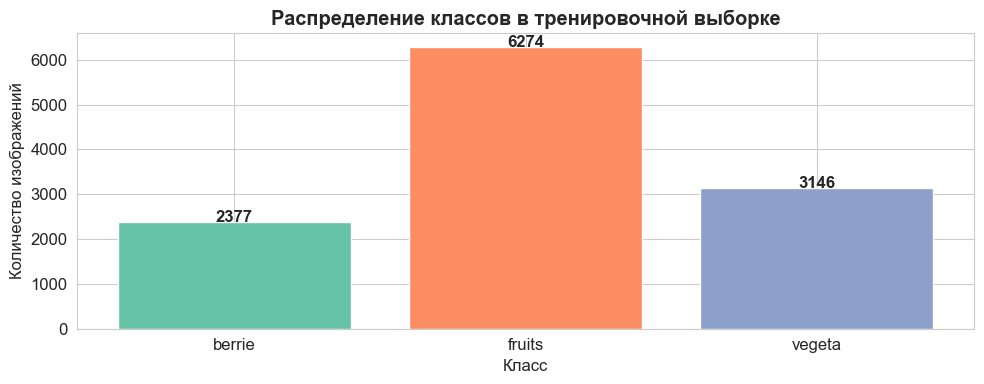

In [37]:
# ── Распределение классов ─────────────────────────────────────────
class_dist = pd.Series(y_train).value_counts().sort_index()
class_dist.index = class_names

plt.figure(figsize=(10, 4))
bars = plt.bar(class_dist.index, class_dist.values,
               color=sns.color_palette('Set2', NUM_CLASSES), edgecolor='white')
for bar, val in zip(bars, class_dist.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 1, str(val),
             ha='center', fontweight='bold')
plt.title('Распределение классов в тренировочной выборке', fontweight='bold')
plt.xlabel('Класс')
plt.ylabel('Количество изображений')
plt.tight_layout()
plt.show()

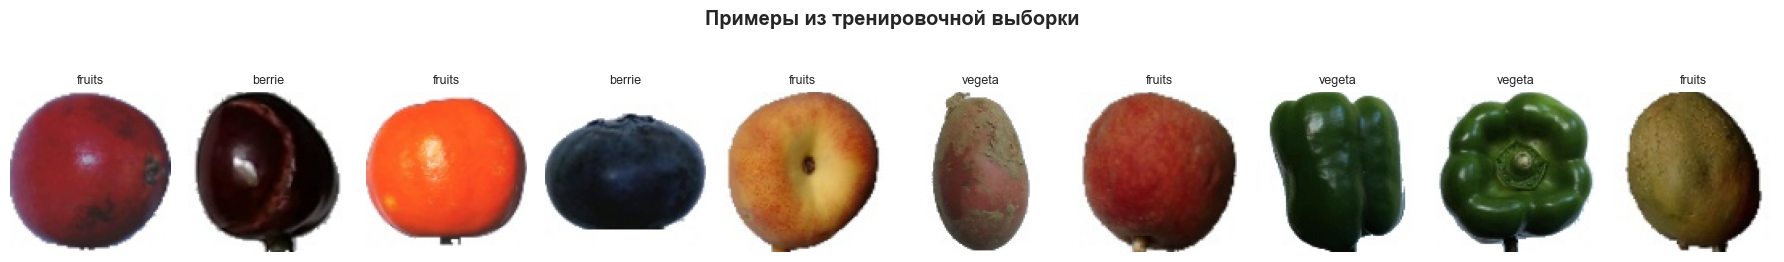

In [38]:
# ── Визуализация примеров из датасета ─────────────────────────────
n_show = min(10, len(X_train))
indices = random.sample(range(len(X_train)), n_show)

fig, axes = plt.subplots(1, n_show, figsize=(18, 3))
for i, idx in enumerate(indices):
    axes[i].imshow(X_train[idx])
    axes[i].set_title(class_names[y_train[idx]], fontsize=9)
    axes[i].axis('off')
plt.suptitle('Примеры из тренировочной выборки', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 2. Вспомогательные функции (лог, графики, метрики)

In [39]:
# ── Лог-файл ─────────────────────────────────────────────────────
LOG_FILE = 'training_log.json'
results_log = []

def save_log():
    with open(LOG_FILE, 'w', encoding='utf-8') as f:
        json.dump(results_log, f, ensure_ascii=False, indent=2)

def log_result(name, history, val_loss, val_acc, test_loss, test_acc):
    train_acc_final = history.history['accuracy'][-1]
    val_acc_final   = history.history['val_accuracy'][-1]
    overfit_gap     = round(float(train_acc_final - val_acc_final), 4)
    entry = {
        'name':           name,
        'timestamp':      datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'epochs_trained': len(history.history['loss']),
        'train_acc':      round(float(train_acc_final), 4),
        'val_acc':        round(float(val_acc_final), 4),
        'test_acc':       round(float(test_acc), 4),
        'test_loss':      round(float(test_loss), 4),
        'overfit_gap':    overfit_gap,   # train_acc - val_acc: > 0.05 = переобучение
        'train_loss':     [round(v, 4) for v in history.history['loss']],
        'val_loss':       [round(v, 4) for v in history.history['val_loss']],
    }
    results_log.append(entry)
    save_log()
    status = '⚠️ ПЕРЕОБУЧЕНИЕ' if overfit_gap > 0.05 else '✅ норма'
    print(f'[LOG] {name}')
    print(f'      train_acc={entry["train_acc"]:.4f} | val_acc={entry["val_acc"]:.4f} | test_acc={entry["test_acc"]:.4f}')
    print(f'      overfit_gap={overfit_gap:+.4f} {status}')
    return entry


def plot_history(history, title=''):
    """Графики loss и accuracy с явным отображением разрыва train/val."""
    epochs = range(1, len(history.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Loss
    axes[0].plot(epochs, history.history['loss'],     'o-', label='Train Loss',  color='#3498db')
    axes[0].plot(epochs, history.history['val_loss'], 's-', label='Val Loss',    color='#e74c3c')
    axes[0].set_title(f'{title}\nLoss', fontweight='bold')
    axes[0].set_xlabel('Эпоха')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    # Закрашиваем разрыв
    axes[0].fill_between(epochs,
                         history.history['loss'],
                         history.history['val_loss'],
                         alpha=0.15, color='red', label='Разрыв')

    # Accuracy
    axes[1].plot(epochs, history.history['accuracy'],     'o-', label='Train Acc', color='#2ecc71')
    axes[1].plot(epochs, history.history['val_accuracy'], 's-', label='Val Acc',   color='#e67e22')
    axes[1].set_title(f'{title}\nAccuracy', fontweight='bold')
    axes[1].set_xlabel('Эпоха')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1.05)
    axes[1].legend()
    axes[1].fill_between(epochs,
                         history.history['accuracy'],
                         history.history['val_accuracy'],
                         alpha=0.15, color='orange', label='Разрыв')

    # Текстовый вывод разрыва по эпохам
    gaps = [a - b for a, b in zip(history.history['accuracy'], history.history['val_accuracy'])]
    max_gap_epoch = gaps.index(max(gaps)) + 1
    print(f'  Макс. разрыв train-val accuracy: {max(gaps):+.4f} на эпохе {max_gap_epoch}')
    print(f'  Финальный разрыв: {gaps[-1]:+.4f}  ({'⚠️ переобучение' if gaps[-1] > 0.05 else '✅ норма'})')

    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(model, X, y_true_int, title='Confusion Matrix'):
    y_pred = np.argmax(model.predict(X, verbose=0), axis=1)
    cm = confusion_matrix(y_true_int, y_pred)
    cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
    plt.title(title, fontweight='bold')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.show()


def evaluate_and_log(model, name, history):
    """Оценивает модель на val и test раздельно — честная финальная метрика."""
    val_loss,  val_acc  = model.evaluate(X_val,  y_val_cat,  verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
    print(f'\n{name}')
    print(f'  Val  Loss/Acc : {val_loss:.4f} / {val_acc:.4f} ({val_acc*100:.2f}%)')
    print(f'  Test Loss/Acc : {test_loss:.4f} / {test_acc:.4f} ({test_acc*100:.2f}%)  ← честная оценка')
    plot_history(history, title=name)
    plot_confusion_matrix(model, X_test, y_test, title=f'Confusion Matrix (Test) — {name}')
    log_result(name, history, val_loss, val_acc, test_loss, test_acc)


print('Вспомогательные функции определены.')


Вспомогательные функции определены.


---
## Задание 1. Базовая CNN

In [40]:
def build_base_model(kernel_size=(3, 3), filters=(32, 64), extra_block=False):
    """
    Базовая CNN:
      Conv(filters[0], kernel_size) → MaxPool
      Conv(filters[1], kernel_size) → MaxPool
      [опц. Conv(128, kernel_size) → MaxPool]
      Flatten → Dense(128, relu) → Dense(NUM_CLASSES, softmax)
    """
    model = Sequential([
        # Блок 1
        Conv2D(filters[0], kernel_size, padding='same', activation='relu',
               input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        MaxPooling2D((2, 2)),

        # Блок 2
        Conv2D(filters[1], kernel_size, padding='same', activation='relu'),
        MaxPooling2D((2, 2)),
    ])

    if extra_block:
        model.add(Conv2D(128, kernel_size, padding='same', activation='relu'))
        model.add(MaxPooling2D((2, 2)))

    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dense(NUM_CLASSES, activation='softmax'))

    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [41]:
# ── 1.1 Создание и обучение базовой модели ────────────────────────
model_base = build_base_model(kernel_size=(3, 3), filters=(32, 64))
model_base.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 40000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     5,120,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,139,907 (19.61 MB)

 Trainable params: 5,139,907 (19.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - accuracy: 0.9125 - loss: 0.2451 - val_accuracy: 0.9934 - val_loss: 0.0229
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.9966 - loss: 0.0144 - val_accuracy: 0.9989 - val_loss: 0.0060
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 89ms/step - accuracy: 0.9997 - loss: 0.0016 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 91ms/step - accuracy: 1.0000 - loss: 4.7330e-04 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 89ms/step - accuracy: 1.0000 - loss: 2.7005e-04 - val_accuracy: 1.0000 - val_loss: 7.9824e-04
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 1.0000 - loss: 1.7011e-04 - val_accuracy: 1.0000 - val_loss: 5.8405e-04
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 1.0000 - loss: 1.1634e-04 - val_accuracy: 1.0000 - val_loss: 5.4071e-04
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 90ms/step - accur

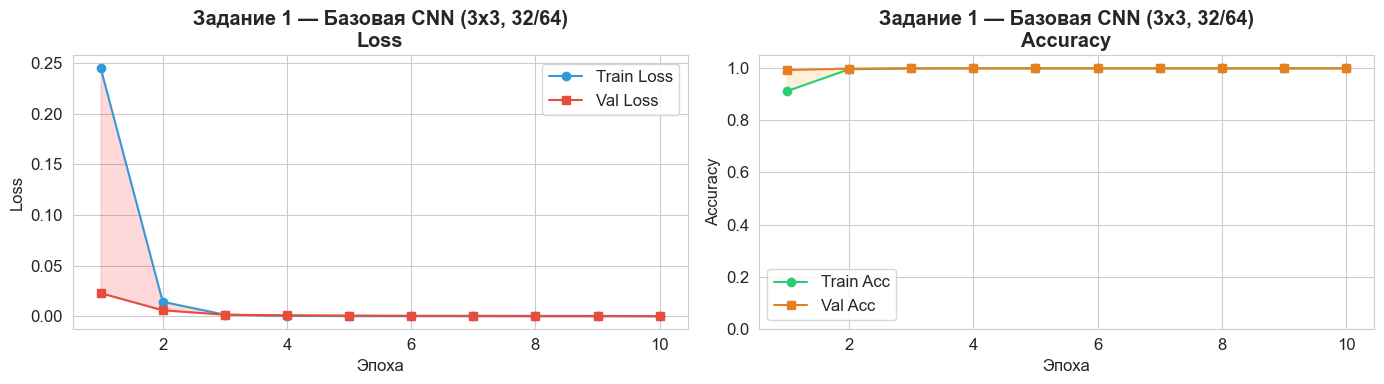

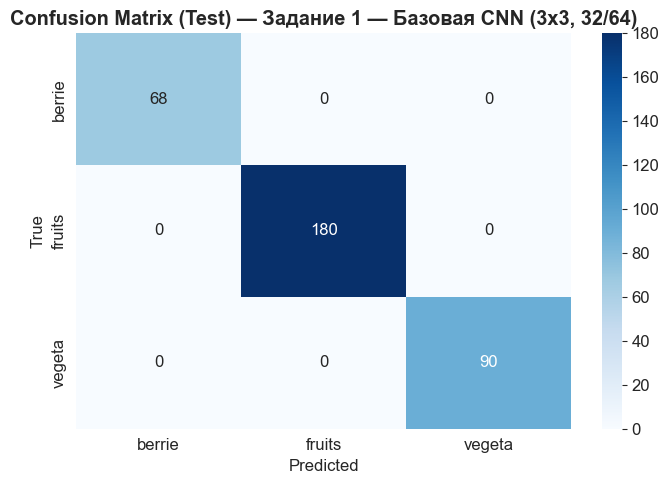

[LOG] Задание 1 — Базовая CNN (3x3, 32/64)
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [42]:
history_base = model_base.fit(
    X_train, y_train_cat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat),
    verbose=1
)

evaluate_and_log(model_base, 'Задание 1 — Базовая CNN (3x3, 32/64)', history_base)

In [43]:
# ── 1.2 Проверка: если val accuracy < 60% — добавляем блок ─────
# Используем X_val (не X_test!) для принятия решения об архитектуре
_, base_acc = model_base.evaluate(X_val, y_val_cat, verbose=0)

if base_acc < 0.60:
    print(f'Val accuracy {base_acc:.2%} — добавляем третий сверточный блок...')
    model_base_ext = build_base_model(kernel_size=(3, 3), filters=(32, 64), extra_block=True)
    model_base_ext.summary()
    history_base_ext = model_base_ext.fit(
        X_train, y_train_cat,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val_cat),
        verbose=1
    )
    evaluate_and_log(model_base_ext, 'Задание 1 — CNN + доп. блок', history_base_ext)
    model_base = model_base_ext
else:
    print(f'Val accuracy {base_acc:.2%} — дополнительный блок не нужен.')


Val accuracy 100.00% — дополнительный блок не нужен.


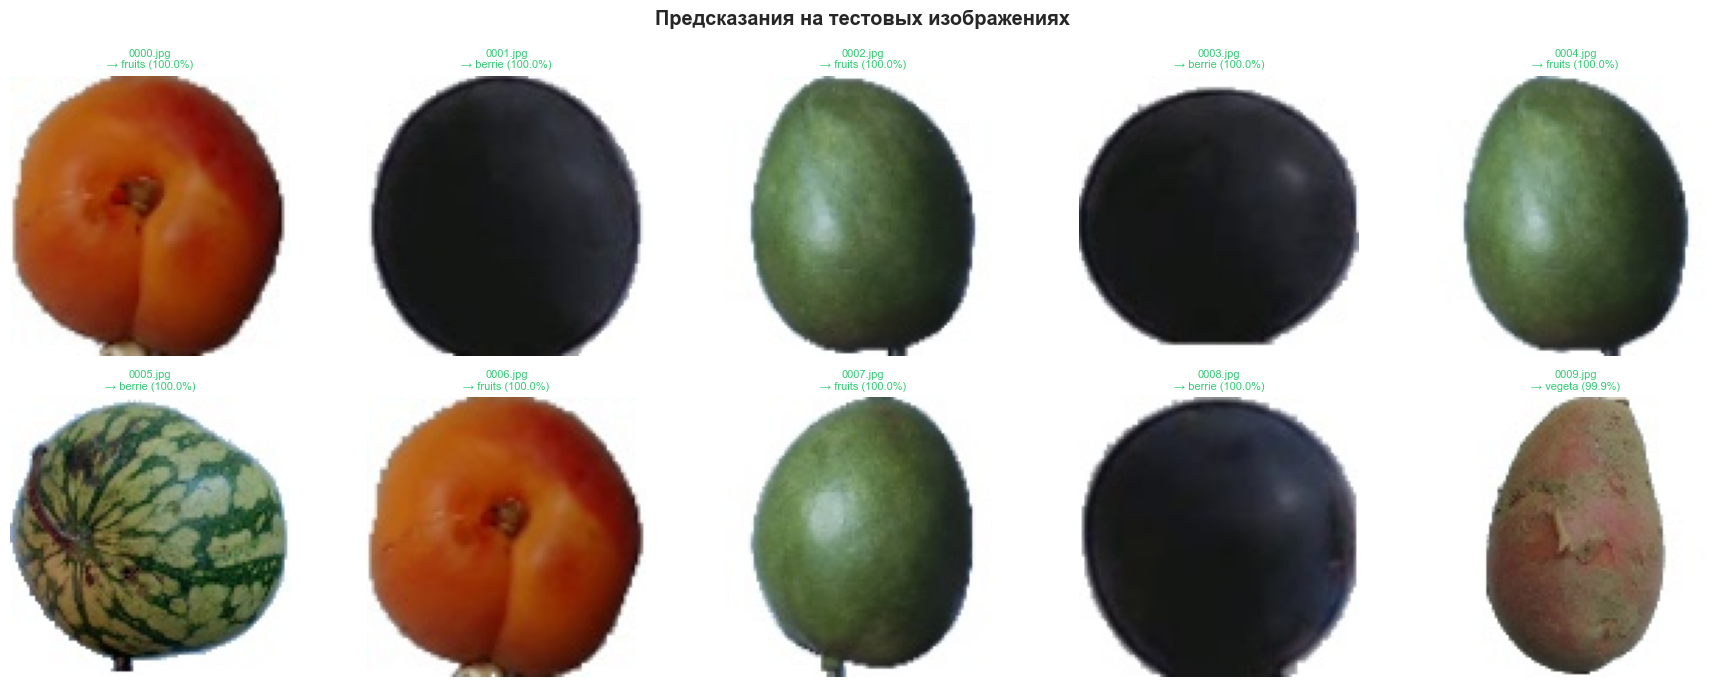

Файл external.jpg не найден.
Положите любое изображение рядом с ноутбуком и переименуйте в external.jpg


In [44]:
# ── Классификация тестовых изображений (без меток) ──────────────
def predict_and_show(model, images, filenames, class_names, n=10):
    """Предсказывает классы для тестовых изображений и показывает результат."""
    n = min(n, len(images))
    preds = model.predict(images[:n], verbose=0)
    pred_classes = np.argmax(preds, axis=1)

    cols = 5
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 3.5))
    axes = axes.flatten()
    for i in range(n):
        axes[i].imshow(images[i])
        pred_name = class_names[pred_classes[i]]
        conf = preds[i].max()
        axes[i].set_title(f'{filenames[i]}\n→ {pred_name} ({conf:.1%})',
                          fontsize=8, color='#2ecc71')
        axes[i].axis('off')
    for j in range(n, len(axes)):
        axes[j].axis('off')
    plt.suptitle('Предсказания на тестовых изображениях', fontweight='bold')
    plt.tight_layout()
    plt.show()

# ── Классификация стороннего изображения ─────────────────────────
EXTERNAL_IMAGE_PATH = 'external.jpg'  # положите рядом с ноутбуком

def predict_external(model, img_path, class_names, img_size=IMG_SIZE):
    """Загружает одно изображение и предсказывает класс."""
    img = Image.open(img_path).convert('RGB')
    img_resized = img.resize((img_size, img_size))
    img_array  = np.array(img_resized, dtype=np.float32) / 255.0
    img_input  = np.expand_dims(img_array, axis=0)

    probs = model.predict(img_input, verbose=0)[0]
    pred_class = class_names[np.argmax(probs)]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(img_resized)
    axes[0].set_title(f'Предсказание: {pred_class}', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    colors = ['#e74c3c' if j == np.argmax(probs) else '#3498db'
              for j in range(len(class_names))]
    axes[1].barh(class_names, probs, color=colors)
    axes[1].set_xlabel('Вероятность')
    axes[1].set_title('Вероятности классов', fontweight='bold')
    axes[1].set_xlim(0, 1)
    for j, v in enumerate(probs):
        axes[1].text(v + 0.01, j, f'{v:.2%}', va='center')
    plt.tight_layout()
    plt.show()
    print(f'Ответ модели: {pred_class} (уверенность: {probs.max():.2%})')

# Показываем предсказания на тестовых изображениях
predict_and_show(model_base, X_unlabeled, unlabeled_filenames, class_names, n=10)

# Классификация стороннего изображения
if os.path.exists(EXTERNAL_IMAGE_PATH):
    predict_external(model_base, EXTERNAL_IMAGE_PATH, class_names)
else:
    print(f'Файл {EXTERNAL_IMAGE_PATH} не найден.')
    print('Положите любое изображение рядом с ноутбуком и переименуйте в external.jpg')


---
## Задание 2. Влияние размера ядра свёртки

=== Ядро 7×7 ===


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 100, 100, 32)   │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 50, 50, 64)     │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 40000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     5,120,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,225,667 (19.93 MB)

 Trainable params: 5,225,667 (19.93 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 42s 218ms/step - accuracy: 0.8711 - loss: 0.3666 - val_accuracy: 0.9722 - val_loss: 0.0709
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 40s 215ms/step - accuracy: 0.9927 - loss: 0.0248 - val_accuracy: 0.9928 - val_loss: 0.0198
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 77s 416ms/step - accuracy: 0.9873 - loss: 0.0362 - val_accuracy: 0.9941 - val_loss: 0.0174
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 40s 218ms/step - accuracy: 0.9984 - loss: 0.0056 - val_accuracy: 0.9998 - val_loss: 0.0017
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 40s 214ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 3.5711e-04
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 40s 214ms/step - accuracy: 1.0000 - loss: 1.6168e-04 - val_accuracy: 1.0000 - val_loss: 1.9671e-04
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 40s 214ms/step - accuracy: 1.0000 - loss: 1.0779e-04 - val_accuracy: 1.0000 - val_loss: 1.3147e-04
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 223ms/step - accura

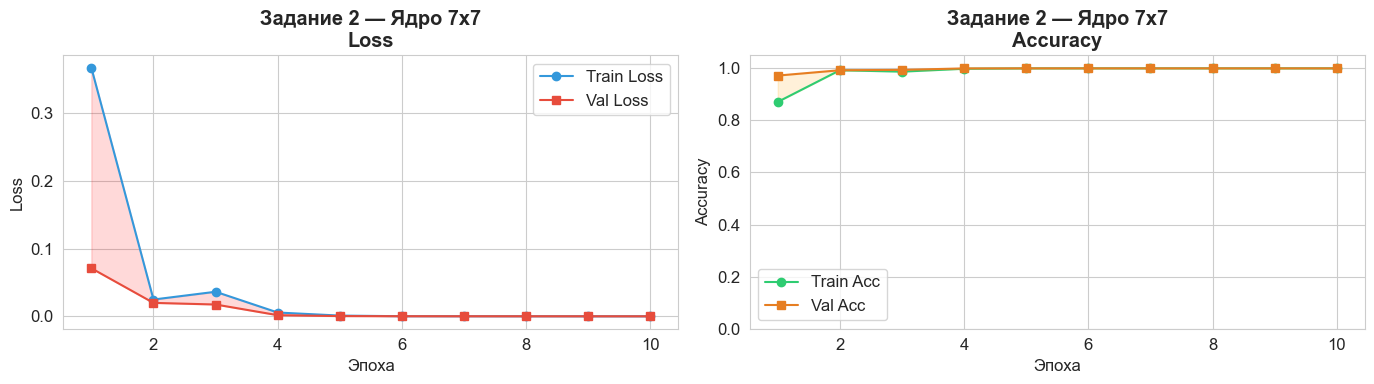

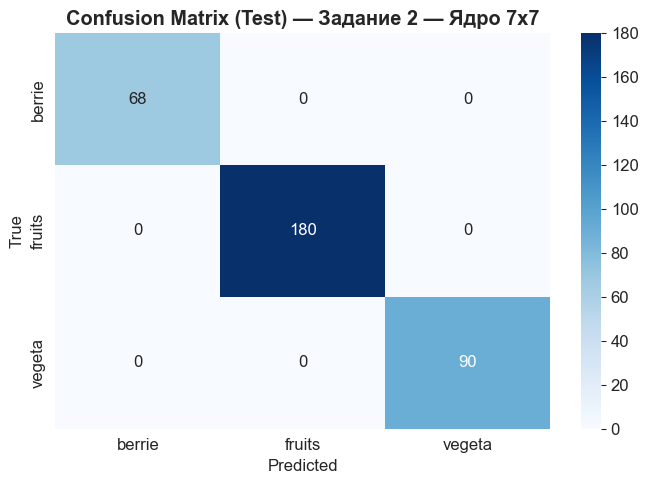

[LOG] Задание 2 — Ядро 7x7
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [45]:
# ── 2.1 Ядро 7×7 ─────────────────────────────────────────────────
model_7x7 = build_base_model(kernel_size=(7, 7), filters=(32, 64))
print('=== Ядро 7×7 ===')
model_7x7.summary()
history_7x7 = model_7x7.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_7x7, 'Задание 2 — Ядро 7x7', history_7x7)

=== Ядро 5×5 ===
Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 27s 139ms/step - accuracy: 0.9031 - loss: 0.2591 - val_accuracy: 0.9835 - val_loss: 0.0467
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 25s 136ms/step - accuracy: 0.9973 - loss: 0.0100 - val_accuracy: 0.9996 - val_loss: 0.0024
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 139ms/step - accuracy: 0.9950 - loss: 0.0165 - val_accuracy: 0.9939 - val_loss: 0.0175
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 139ms/step - accuracy: 0.9971 - loss: 0.0091 - val_accuracy: 0.9979 - val_loss: 0.0073
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 25s 137ms/step - accuracy: 1.0000 - loss: 8.5437e-04 - val_accuracy: 1.0000 - val_loss: 1.6111e-04
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 25s 137ms/step - accuracy: 1.0000 - loss: 1.6296e-04 - val_accuracy: 1.0000 - val_loss: 1.6844e-04
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 25s 136ms/step - accuracy: 1.0000 - loss: 4.9344e-05 - val_accuracy: 1.0000 - val_loss: 7.4556e-05
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 25

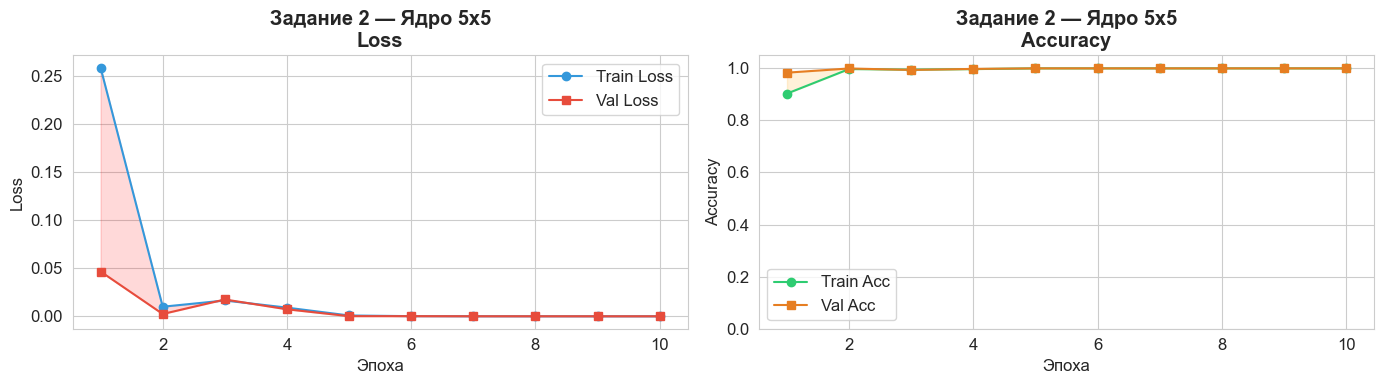

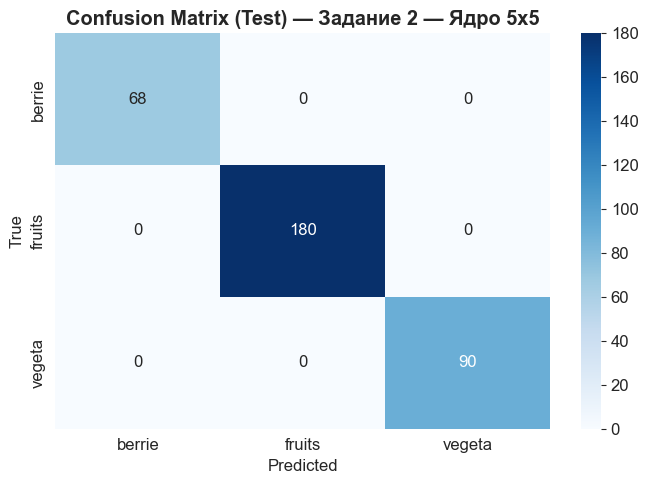

[LOG] Задание 2 — Ядро 5x5
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [46]:
# ── 2.2 Ядро 5×5 ─────────────────────────────────────────────────
model_5x5 = build_base_model(kernel_size=(5, 5), filters=(32, 64))
print('=== Ядро 5×5 ===')
history_5x5 = model_5x5.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_5x5, 'Задание 2 — Ядро 5x5', history_5x5)

=== Первый 5×5, второй 3×3 ===
Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 19s 96ms/step - accuracy: 0.9252 - loss: 0.2219 - val_accuracy: 0.9947 - val_loss: 0.0193
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 93ms/step - accuracy: 0.9982 - loss: 0.0089 - val_accuracy: 0.9595 - val_loss: 0.0955
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 94ms/step - accuracy: 0.9975 - loss: 0.0097 - val_accuracy: 0.9994 - val_loss: 0.0074
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 93ms/step - accuracy: 0.9999 - loss: 0.0016 - val_accuracy: 0.9998 - val_loss: 7.4478e-04
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 94ms/step - accuracy: 1.0000 - loss: 1.2925e-04 - val_accuracy: 1.0000 - val_loss: 2.9120e-04
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 93ms/step - accuracy: 1.0000 - loss: 7.3815e-05 - val_accuracy: 1.0000 - val_loss: 1.8763e-04
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 17s 93ms/step - accuracy: 1.0000 - loss: 5.0385e-05 - val_accuracy: 1.0000 - val_loss: 1.5577e-04
Epoch 8/10
185/185 ━━━━━━━━━━━━

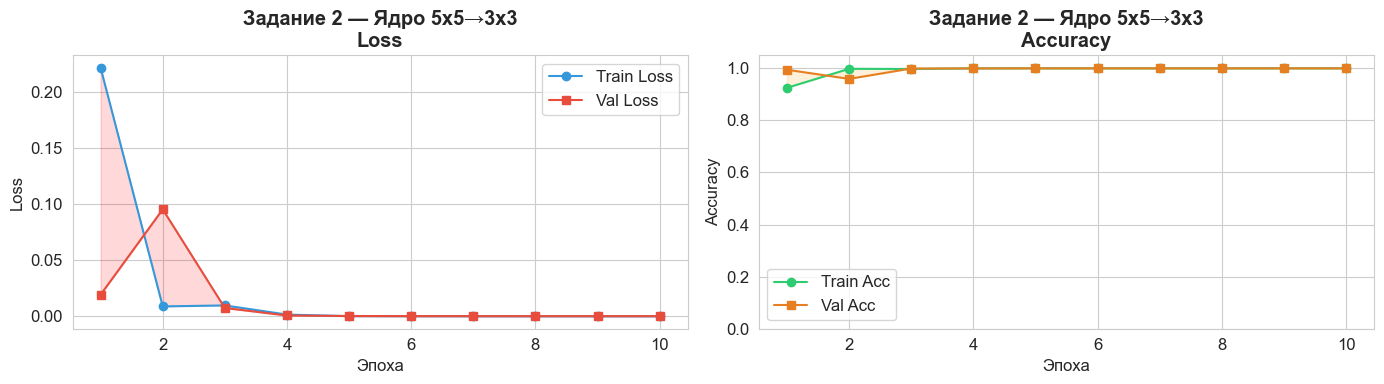

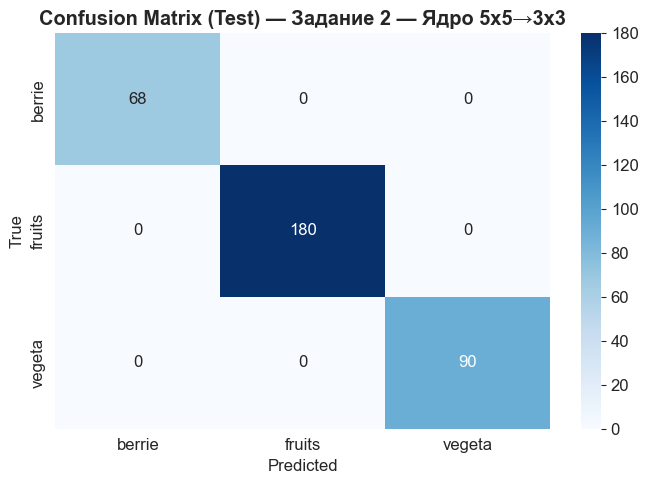

[LOG] Задание 2 — Ядро 5x5→3x3
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [47]:
# ── 2.3 Первый фильтр 5×5, остальные 3×3 ─────────────────────────
model_5_3 = Sequential([
    Conv2D(32, (5, 5), padding='same', activation='relu',
           input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(NUM_CLASSES, activation='softmax')
])
model_5_3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print('=== Первый 5×5, второй 3×3 ===')
history_5_3 = model_5_3.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_5_3, 'Задание 2 — Ядро 5x5→3x3', history_5_3)

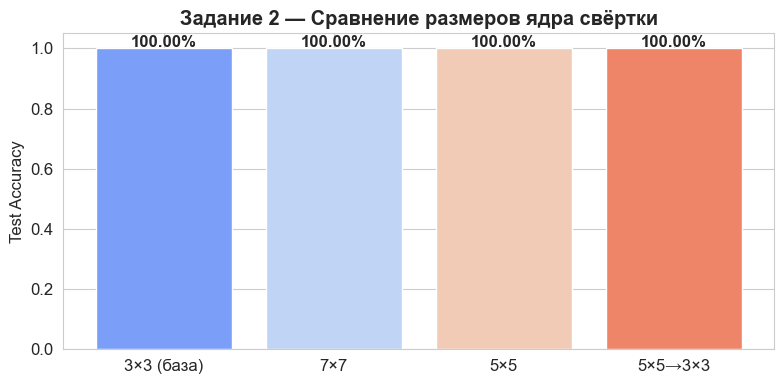

In [48]:
# ── Сравнение ядер ────────────────────────────────────────────────
kernel_names = ['3×3 (база)', '7×7', '5×5', '5×5→3×3']
kernel_accs  = [
    results_log[-4]['test_acc'] if len(results_log) >= 4 else 0,
    results_log[-3]['test_acc'] if len(results_log) >= 3 else 0,
    results_log[-2]['test_acc'] if len(results_log) >= 2 else 0,
    results_log[-1]['test_acc'] if len(results_log) >= 1 else 0,
]
# Берём результаты из лога по имени, надёжнее
def get_acc(name):
    for r in results_log:
        if name in r['name']:
            return r['test_acc']
    return 0

kernel_accs = [
    get_acc('Базовая CNN'),
    get_acc('7x7'),
    get_acc('5x5'),
    get_acc('5x5→3x3'),
]

plt.figure(figsize=(8, 4))
bars = plt.bar(kernel_names, kernel_accs,
               color=sns.color_palette('coolwarm', 4), edgecolor='white')
for bar, v in zip(bars, kernel_accs):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.005,
             f'{v:.2%}', ha='center', fontweight='bold')
plt.title('Задание 2 — Сравнение размеров ядра свёртки', fontweight='bold')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

---
## Задание 3. Влияние количества фильтров

=== Фильтры 64/128 ===
Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 44s 233ms/step - accuracy: 0.9332 - loss: 0.2132 - val_accuracy: 0.9981 - val_loss: 0.0093
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 232ms/step - accuracy: 0.9966 - loss: 0.0136 - val_accuracy: 0.9998 - val_loss: 0.0023
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 231ms/step - accuracy: 0.9998 - loss: 0.0012 - val_accuracy: 0.9998 - val_loss: 6.9940e-04
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 232ms/step - accuracy: 1.0000 - loss: 1.5364e-04 - val_accuracy: 1.0000 - val_loss: 2.6622e-04
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 230ms/step - accuracy: 1.0000 - loss: 7.9388e-05 - val_accuracy: 1.0000 - val_loss: 1.8475e-04
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 42s 229ms/step - accuracy: 1.0000 - loss: 5.5510e-05 - val_accuracy: 1.0000 - val_loss: 1.5736e-04
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 230ms/step - accuracy: 1.0000 - loss: 4.1233e-05 - val_accuracy: 1.0000 - val_loss: 1.1947e-04
Epoch 8/10
185/185 ━━━━━

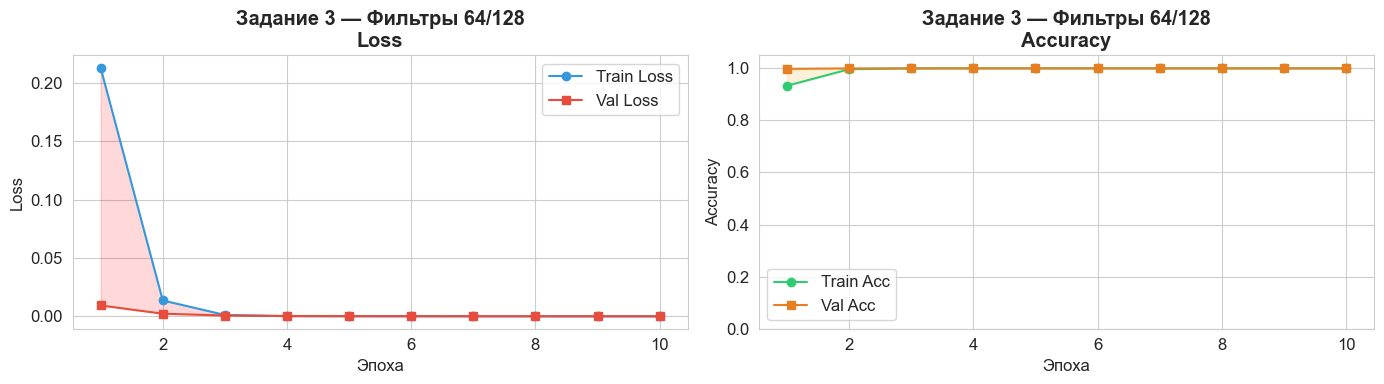

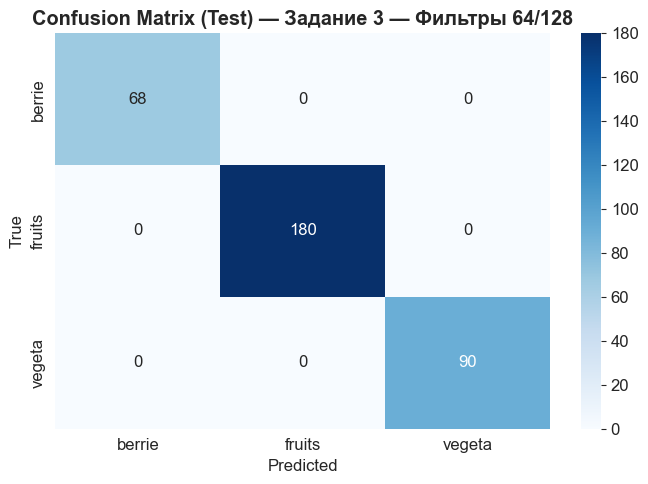

[LOG] Задание 3 — Фильтры 64/128
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [49]:
# ── 3.1 Фильтры 64 и 128 ─────────────────────────────────────────
model_64_128 = build_base_model(kernel_size=(3, 3), filters=(64, 128))
print('=== Фильтры 64/128 ===')
history_64_128 = model_64_128.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_64_128, 'Задание 3 — Фильтры 64/128', history_64_128)

=== Фильтры 8/16 ===
Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.8908 - loss: 0.2993 - val_accuracy: 0.9905 - val_loss: 0.0479
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9958 - loss: 0.0231 - val_accuracy: 0.9981 - val_loss: 0.0120
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9971 - loss: 0.0124 - val_accuracy: 0.9992 - val_loss: 0.0060
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9997 - loss: 0.0029 - val_accuracy: 0.9996 - val_loss: 0.0032
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9989 - loss: 0.0055 - val_accuracy: 0.9998 - val_loss: 0.0033
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 1.0000 - loss: 8.6401e-04 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 1.0000 - loss: 4.9530e-04 - val_accuracy: 1.0000 - val_loss: 7.7739e-04
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy:

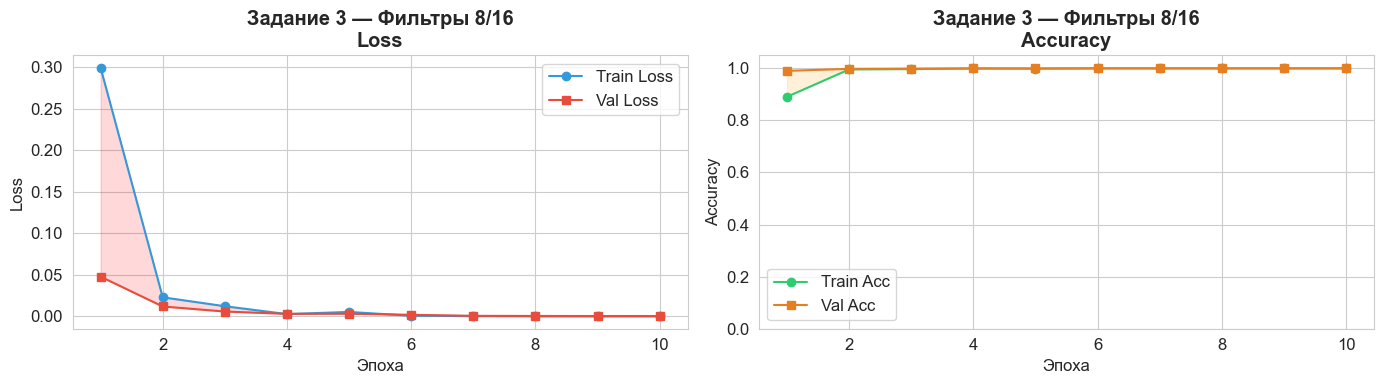

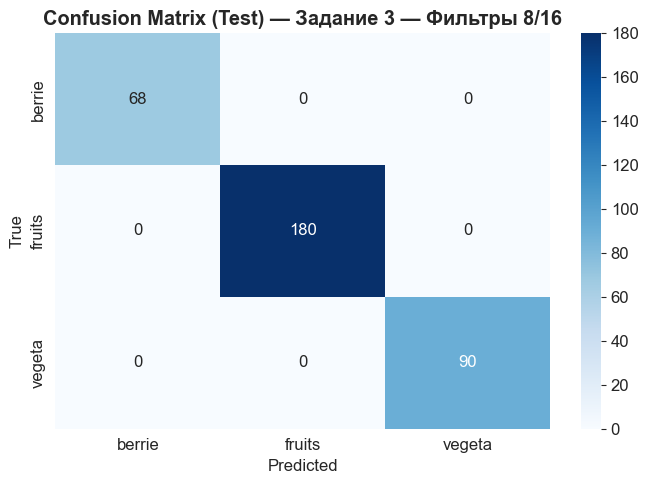

[LOG] Задание 3 — Фильтры 8/16
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [50]:
# ── 3.2 Фильтры 8 и 16 ───────────────────────────────────────────
model_8_16 = build_base_model(kernel_size=(3, 3), filters=(8, 16))
print('=== Фильтры 8/16 ===')
history_8_16 = model_8_16.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_8_16, 'Задание 3 — Фильтры 8/16', history_8_16)

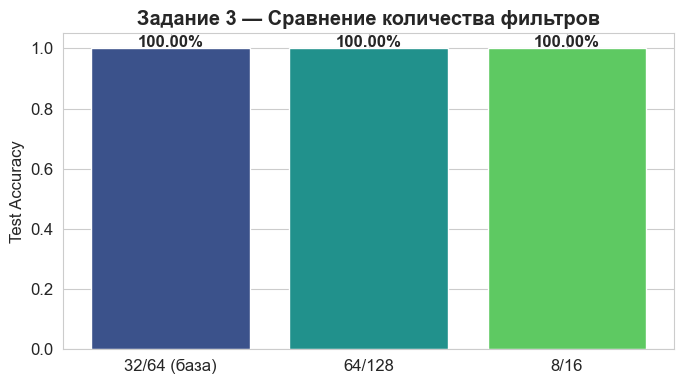

In [51]:
# ── Сравнение количества фильтров ─────────────────────────────────
filter_names = ['32/64 (база)', '64/128', '8/16']
filter_accs  = [get_acc('Базовая CNN'), get_acc('64/128'), get_acc('8/16')]

plt.figure(figsize=(7, 4))
bars = plt.bar(filter_names, filter_accs,
               color=sns.color_palette('viridis', 3), edgecolor='white')
for bar, v in zip(bars, filter_accs):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.005,
             f'{v:.2%}', ha='center', fontweight='bold')
plt.title('Задание 3 — Сравнение количества фильтров', fontweight='bold')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

---
## Задание 4. Влияние чередования слоёв

=== Двойные сверточные блоки ===


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)              │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 100, 100, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 50, 50, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 40000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │     5,120,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,186,083 (19.78 MB)

 Trainable params: 5,186,083 (19.78 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 224ms/step - accuracy: 0.9119 - loss: 0.2235 - val_accuracy: 0.9432 - val_loss: 0.1726
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 222ms/step - accuracy: 0.9920 - loss: 0.0255 - val_accuracy: 0.9932 - val_loss: 0.0169
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 82s 221ms/step - accuracy: 0.9952 - loss: 0.0182 - val_accuracy: 0.9977 - val_loss: 0.0094
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 221ms/step - accuracy: 0.9974 - loss: 0.0083 - val_accuracy: 0.9989 - val_loss: 0.0041
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 222ms/step - accuracy: 0.9997 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 4.6699e-04
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 221ms/step - accuracy: 1.0000 - loss: 3.2051e-05 - val_accuracy: 1.0000 - val_loss: 1.4406e-04
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 42s 227ms/step - accuracy: 1.0000 - loss: 1.5850e-05 - val_accuracy: 1.0000 - val_loss: 9.0393e-05
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 223ms/step - accura

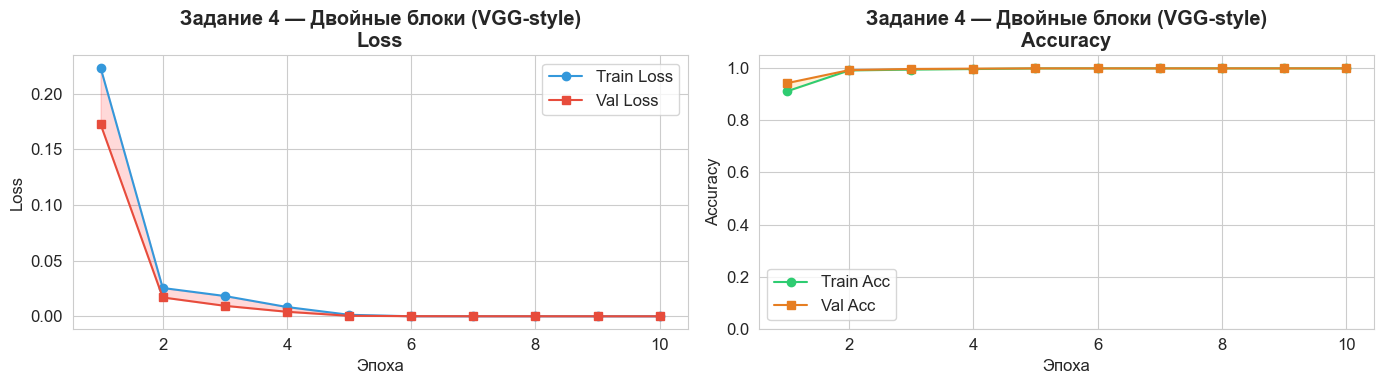

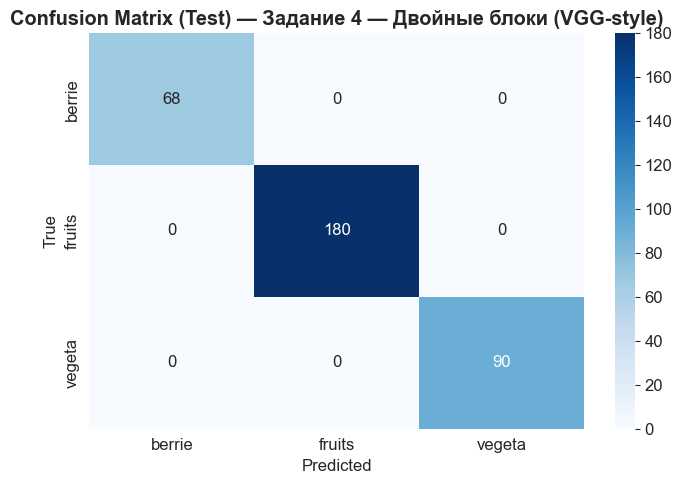

[LOG] Задание 4 — Двойные блоки (VGG-style)
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [52]:
# ── 4.1 Двойные сверточные блоки перед каждым пулингом ───────────
model_double = Sequential([
    # Блок 1×2
    Conv2D(32, (3, 3), padding='same', activation='relu',
           input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    # Блок 2×2
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dense(NUM_CLASSES, activation='softmax')
])
model_double.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print('=== Двойные сверточные блоки ===')
model_double.summary()
history_double = model_double.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_double, 'Задание 4 — Двойные блоки (VGG-style)', history_double)

=== Stride=2 вместо MaxPooling ===


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 50, 50, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 25, 25, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │     2,560,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,570,659 (9.81 MB)

 Trainable params: 2,570,659 (9.81 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.8997 - loss: 0.2660 - val_accuracy: 0.9894 - val_loss: 0.0371
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9941 - loss: 0.0220 - val_accuracy: 0.9975 - val_loss: 0.0131
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9996 - loss: 0.0033 - val_accuracy: 0.9975 - val_loss: 0.0053
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9984 - loss: 0.0064 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 1.0000 - loss: 3.5226e-04 - val_accuracy: 1.0000 - val_loss: 6.9785e-04
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 1.0000 - loss: 1.7299e-04 - val_accuracy: 1.0000 - val_loss: 6.6356e-04
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 1.0000 - loss: 1.1159e-04 - val_accuracy: 1.0000 - val_loss: 3.9441e-04
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 1.0000 -

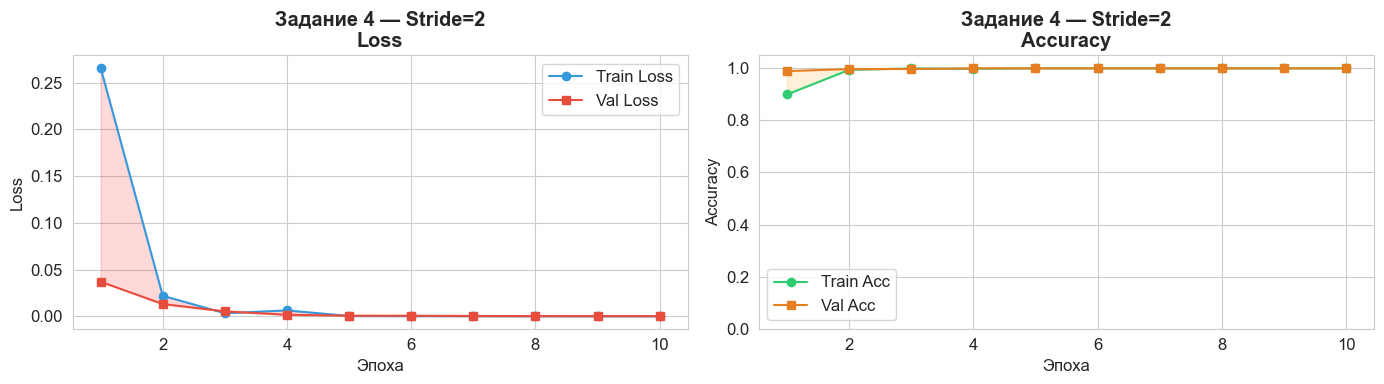

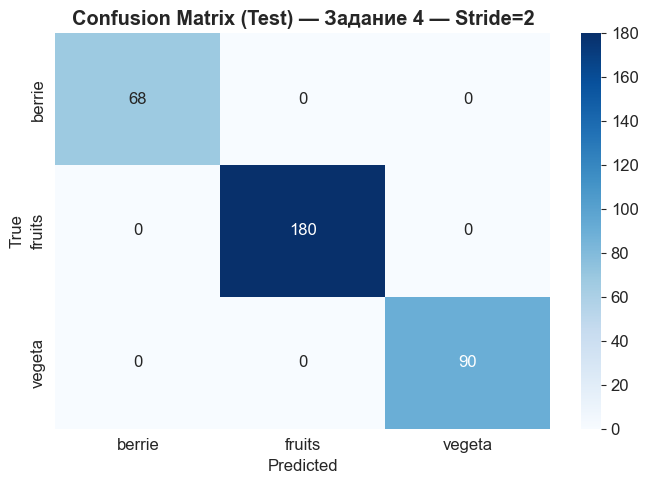

[LOG] Задание 4 — Stride=2
      train_acc=1.0000 | val_acc=1.0000 | test_acc=1.0000
      overfit_gap=+0.0000 ✅ норма


In [53]:
# ── 4.2 Свертка со страйдом вместо пулинга ────────────────────────
model_stride = Sequential([
    Conv2D(32, (3, 3), strides=2, padding='same', activation='relu',
           input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    Conv2D(32, (3, 3), strides=2, padding='same', activation='relu'),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(NUM_CLASSES, activation='softmax')
])
model_stride.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print('=== Stride=2 вместо MaxPooling ===')
model_stride.summary()
history_stride = model_stride.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_stride, 'Задание 4 — Stride=2', history_stride)

---
## Задание 5. BatchNormalization + Dropout

=== BatchNorm + Dropout ===


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_26 (Conv2D)              │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 40000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │     5,120,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,140,291 (19.61 MB)

 Trainable params: 5,140,099 (19.61 MB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 209ms/step - accuracy: 0.8213 - loss: 1.0882 - val_accuracy: 0.6008 - val_loss: 2.1023
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 39s 210ms/step - accuracy: 0.9294 - loss: 0.1647 - val_accuracy: 0.7177 - val_loss: 1.1414
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 39s 208ms/step - accuracy: 0.9551 - loss: 0.0936 - val_accuracy: 0.9979 - val_loss: 0.0109
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 201ms/step - accuracy: 0.9599 - loss: 0.0875 - val_accuracy: 0.9968 - val_loss: 0.0102
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 200ms/step - accuracy: 0.9658 - loss: 0.0869 - val_accuracy: 0.9616 - val_loss: 0.1128
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 200ms/step - accuracy: 0.9626 - loss: 0.0970 - val_accuracy: 0.9996 - val_loss: 0.0030
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 199ms/step - accuracy: 0.9714 - loss: 0.0624 - val_accuracy: 0.9987 - val_loss: 0.0037
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 200ms/step - accuracy: 0.9852 - loss: 0

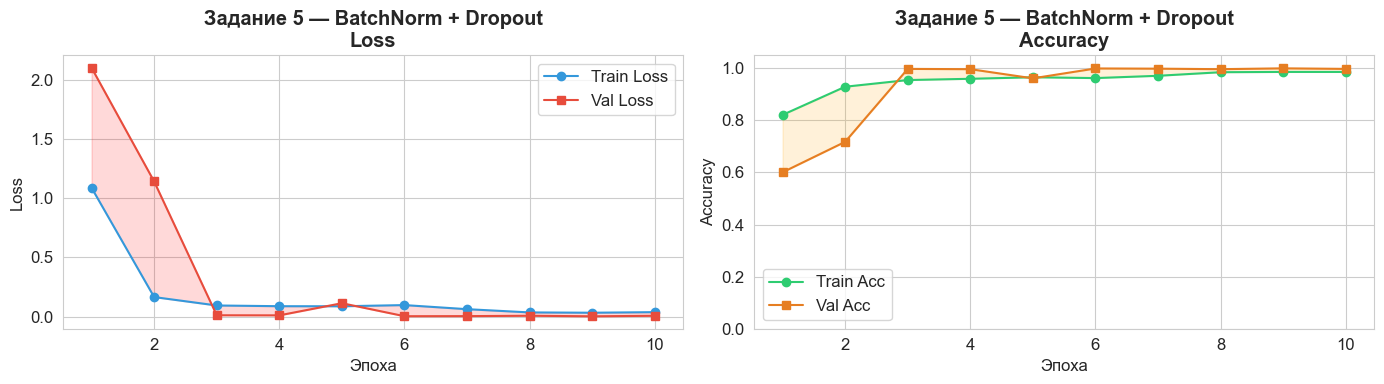

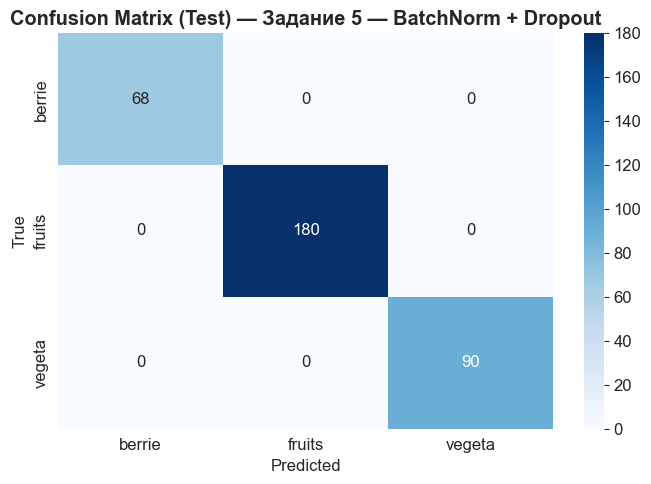

[LOG] Задание 5 — BatchNorm + Dropout
      train_acc=0.9862 | val_acc=0.9979 | test_acc=1.0000
      overfit_gap=-0.0117 ✅ норма


In [54]:
# ── BatchNorm после каждого Conv2D, Dropout после Dense ───────────
model_bn_do = Sequential([
    # Блок 1
    Conv2D(32, (3, 3), padding='same', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    BatchNormalization(),
    layers.Activation('relu'),
    MaxPooling2D((2, 2)),

    # Блок 2
    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    layers.Activation('relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])
model_bn_do.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print('=== BatchNorm + Dropout ===')
model_bn_do.summary()
history_bn_do = model_bn_do.fit(
    X_train, y_train_cat,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_cat), verbose=1
)
evaluate_and_log(model_bn_do, 'Задание 5 — BatchNorm + Dropout', history_bn_do)

---
## Задание 6. Сравнение всех моделей — выбор лучшей

In [56]:
# ── Таблица результатов ───────────────────────────────────────────
log_df = pd.DataFrame(results_log)[['name', 'train_acc', 'val_acc', 'test_acc', 'test_loss', 'overfit_gap', 'epochs_trained']]
log_df = log_df.sort_values('test_acc', ascending=False).reset_index(drop=True)
print('Таблица результатов всех экспериментов:')
display(log_df)

Таблица результатов всех экспериментов:


,name,train_acc,val_acc,test_acc,test_loss,overfit_gap,epochs_trained
0,"Задание 1 — Базовая CNN (3x3, 32/64)",1.0000,1.0000,1.0,0.0002,0.0000,10
1,Задание 2 — Ядро 7x7,1.0000,1.0000,1.0,0.0000,0.0000,10
2,Задание 2 — Ядро 5x5,1.0000,1.0000,1.0,0.0000,0.0000,10
3,Задание 2 — Ядро 5x5→3x3,1.0000,1.0000,1.0,0.0002,0.0000,10
4,Задание 3 — Фильтры 64/128,1.0000,1.0000,1.0,0.0001,0.0000,10
5,Задание 3 — Фильтры 8/16,1.0000,1.0000,1.0,0.0003,0.0000,10
6,Задание 4 — Двойные блоки (VGG-style),1.0000,1.0000,1.0,0.0000,0.0000,10
7,Задание 4 — Stride=2,1.0000,1.0000,1.0,0.0006,0.0000,10
8,Задание 5 — BatchNorm + Dropout,0.9862,0.9979,1.0,0.0017,-0.0117,10


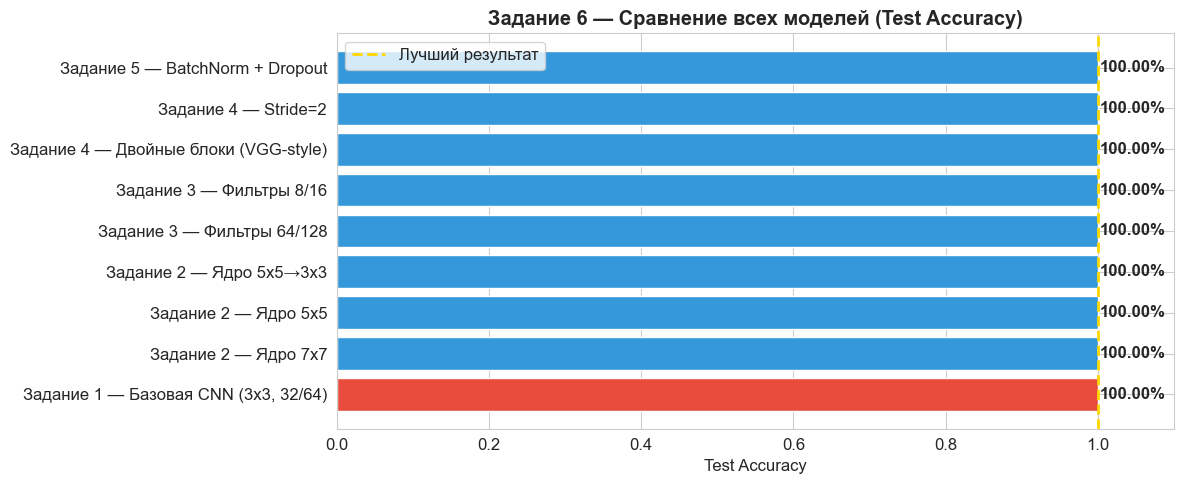

In [57]:
# ── Визуализация сравнения ────────────────────────────────────────
plt.figure(figsize=(12, 5))
colors = ['#e74c3c' if i == 0 else '#3498db' for i in range(len(log_df))]
bars = plt.barh(log_df['name'], log_df['test_acc'], color=colors, edgecolor='white')
for bar, v in zip(bars, log_df['test_acc']):
    plt.text(v + 0.003, bar.get_y() + bar.get_height()/2,
             f'{v:.2%}', va='center', fontweight='bold')
plt.axvline(log_df['test_acc'].max(), color='gold', linestyle='--', linewidth=2, label='Лучший результат')
plt.title('Задание 6 — Сравнение всех моделей (Test Accuracy)', fontweight='bold')
plt.xlabel('Test Accuracy')
plt.xlim(0, 1.1)
plt.legend()
plt.tight_layout()
plt.show()

In [58]:
# ── Определяем лучшую модель и сохраняем ─────────────────────────
best_name = log_df.iloc[0]['name']
print(f'Лучшая модель: {best_name} — Test Accuracy: {log_df.iloc[0]["test_acc"]:.2%}')

# Словарь моделей
all_models = {
    'Задание 1 — Базовая CNN (3x3, 32/64)': model_base,
    'Задание 2 — Ядро 7x7':                 model_7x7,
    'Задание 2 — Ядро 5x5':                 model_5x5,
    'Задание 2 — Ядро 5x5→3x3':             model_5_3,
    'Задание 3 — Фильтры 64/128':            model_64_128,
    'Задание 3 — Фильтры 8/16':              model_8_16,
    'Задание 4 — Двойные блоки (VGG-style)': model_double,
    'Задание 4 — Stride=2':                  model_stride,
    'Задание 5 — BatchNorm + Dropout':       model_bn_do,
}

# Поиск лучшей модели
best_model = None
for k, m in all_models.items():
    if k in best_name or best_name in k:
        best_model = m
        break

if best_model is None:
    best_model = model_base  # fallback
    print('(Используем базовую модель как лучшую по умолчанию)')

# Сохранение
BEST_MODEL_PATH = 'best_model.keras'
best_model.save(BEST_MODEL_PATH)
print(f'Лучшая модель сохранена: {BEST_MODEL_PATH}')

Лучшая модель: Задание 1 — Базовая CNN (3x3, 32/64) — Test Accuracy: 100.00%
Лучшая модель сохранена: best_model.keras


In [60]:
# ── Загрузка сохранённой модели и классификация стороннего файла ──
from keras.models import load_model
loaded_model = load_model(BEST_MODEL_PATH)
print('Модель загружена из файла:', BEST_MODEL_PATH)

# Классификация стороннего изображения
EXTERNAL_IMAGE_PATH = 'path/to/external/image.jpg'  # ← замените путь

if os.path.exists(EXTERNAL_IMAGE_PATH):
    predict_external(loaded_model, EXTERNAL_IMAGE_PATH, class_names)
else:
    print(f'Файл не найден: {EXTERNAL_IMAGE_PATH}')
    print('Замените EXTERNAL_IMAGE_PATH на путь к реальному изображению.')

Модель загружена из файла: best_model.keras
Файл не найден: path/to/external/image.jpg
Замените EXTERNAL_IMAGE_PATH на путь к реальному изображению.


In [61]:
# ── Итоговый лог-файл ─────────────────────────────────────────────
print(f'Лог-файл: {LOG_FILE}')
with open(LOG_FILE, 'r', encoding='utf-8') as f:
    print(f.read())

Лог-файл: training_log.json
[
  {
    "name": "Задание 1 — Базовая CNN (3x3, 32/64)",
    "timestamp": "2026-04-16 22:43:19",
    "epochs_trained": 10,
    "train_acc": 1.0,
    "val_acc": 1.0,
    "test_acc": 1.0,
    "test_loss": 0.0002,
    "overfit_gap": 0.0,
    "train_loss": [
      0.2451,
      0.0144,
      0.0016,
      0.0005,
      0.0003,
      0.0002,
      0.0001,
      0.0001,
      0.0001,
      0.0
    ],
    "val_loss": [
      0.0229,
      0.006,
      0.0016,
      0.0011,
      0.0008,
      0.0006,
      0.0005,
      0.0004,
      0.0004,
      0.0003
    ]
  },
  {
    "name": "Задание 2 — Ядро 7x7",
    "timestamp": "2026-04-16 22:50:50",
    "epochs_trained": 10,
    "train_acc": 1.0,
    "val_acc": 1.0,
    "test_acc": 1.0,
    "test_loss": 0.0,
    "overfit_gap": 0.0,
    "train_loss": [
      0.3666,
      0.0248,
      0.0362,
      0.0056,
      0.0011,
      0.0002,
      0.0001,
      0.0001,
      0.0001,
      0.0
    ],
    "val_loss": [
      0.07